# 02 Embeddings

**Question.** Which embedding model and topic vector make the cosine of a prompt to a topic the
best signal for "this is the prompt's topic"?

There is no shortlist: the judge rates every topic of the forest (decided 24 Nov 2026).
Embeddings still matter in three places:
- the cosine part of the fit, `s = gamma * judge + (1 - gamma) * calibrated cosine`;
- the fit of pairs the judge did not rate (old prompts against new topics);
- the evaluation fit that scores every method the same way (notebook 05).

**Method.** For every prompt whose gold topic already exists, all topics of the gold forest are
ranked by cosine to the prompt (the gold forest is replayed: prompt *t* against the gold
placement of prompts 1..t-1). Reported: top-1 accuracy (the gold topic is strictly the most
similar; a tie counts as a miss) and the mean rank of the gold topic. Gold labels are **drafts** (see 01).

Backends: two local sentence-transformers models (`all-MiniLM-L6-v2`, `bge-small-en-v1.5`) and
TF-IDF as a lexical floor. An API embedding model is not compared (no key). Topic vector:
`centroid` (mean of the topic's prompts), `label` (the topic name) or `mix` (the mean of the two
cosines).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forest import config, viz
from forest.embed import Embedder, fit_calibration
from forest.evaluate import nearest_topic
from forest.io import SESSION_IDS, load_gold, load_sessions

viz.style()
cfg = config.load()
sessions = load_sessions()
golds = {sid: load_gold(sid) for sid in SESSION_IDS}
BACKENDS = ["minilm", "bge-small", "tfidf"]
OPTIONS = ["centroid", "label", "mix"]
FIG = Path(cfg["paths"]["figures"])
MET = Path(cfg["paths"]["metrics"])

## Cosine calibration per backend
Raw cosines live on different scales per model, so they are mapped to [0, 1] before they are
mixed with the judge. Rule: `lo` = median cosine of a prompt to the gold topics of the *other*
sessions (unrelated); `hi` = 75th percentile of a prompt's cosine to its own gold topic label.
The config holds these values.

In [2]:
emb = {b: Embedder(cfg, b) for b in BACKENDS}
cal = pd.DataFrame({b: fit_calibration(emb[b], sessions, golds) for b in ["minilm", "bge-small"]}).T
cal["config lo"] = [cfg["scores"]["calibration"][b]["lo"] for b in cal.index]
cal["config hi"] = [cfg["scores"]["calibration"][b]["hi"] for b in cal.index]
cal

,lo,hi,config lo,config hi
minilm,0.046,0.555,0.046,0.555
bge-small,0.560,0.776,0.560,0.776


## Which cosine finds the gold topic?

In [3]:
frames = []
for b in BACKENDS:
    for opt in OPTIONS:
        for sid, s in sessions.items():
            d = nearest_topic(emb[b], s, golds[sid], opt)
            d["backend"], d["option"] = b, opt
            frames.append(d)
ranks = pd.concat(frames, ignore_index=True)
table = ranks.groupby(["backend", "option"]).agg(top1=("top1", "mean"), mean_rank=("rank", "mean")).round(3)
table.to_csv(MET / "02_nearest_topic.csv")
print("prompts scored per (backend, option):", len(ranks) // (len(BACKENDS) * len(OPTIONS)),
      "| topics per forest: mean", round(ranks["n_topics"].mean(), 1), "max", ranks["n_topics"].max())
table

prompts scored per (backend, option): 57 | topics per forest: mean 8.1 max 12


top1  mean_rank
backend   option                    
bge-small centroid  0.544      2.456
          label     0.614      1.982
          mix       0.702      1.719
minilm    centroid  0.702      1.684
          label     0.737      1.561
          mix       0.825      1.263
tfidf     centroid  0.509      3.684
          label     0.351      5.509
          mix       0.632      2.965

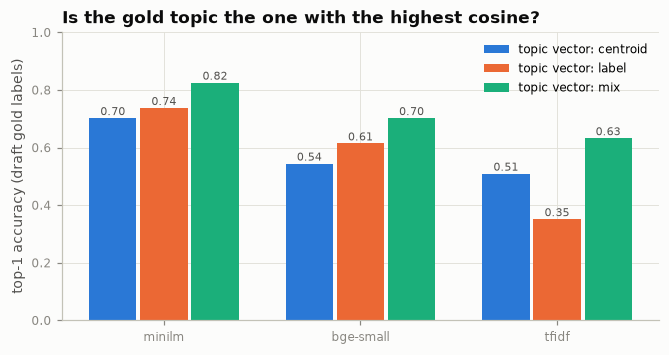

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
width = 0.26
x = np.arange(len(BACKENDS))
for i, opt in enumerate(OPTIONS):
    vals = [table.loc[(b, opt), "top1"] for b in BACKENDS]
    ax.bar(x + (i - 1) * width, vals, width - 0.02, color=viz.SLOTS[i], label=f"topic vector: {opt}")
    for xb, v in zip(x + (i - 1) * width, vals):
        ax.annotate(f"{v:.2f}", (xb, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7, color=viz.TEXT_2)
ax.set_xticks(x, BACKENDS)
ax.set_ylim(0, 1)
ax.set_ylabel("top-1 accuracy (draft gold labels)")
ax.set_title("Is the gold topic the one with the highest cosine?")
ax.legend(loc="upper right")
viz.save(fig, FIG / "02_embedding_top1.png")

## Choice
Best backend and topic vector by top-1 accuracy, then by mean rank.

In [5]:
best = table.sort_values(["top1", "mean_rank"], ascending=[False, True]).index[0]
print(f"best: backend={best[0]}, topic vector={best[1]}; top-1={table.loc[best, 'top1']}, "
      f"mean rank={table.loc[best, 'mean_rank']}")
print(f"config: backend={cfg['embed']['backend']}, topic vector={cfg['embed']['topic_vector']}")
assert (cfg["embed"]["backend"], cfg["embed"]["topic_vector"]) == best, "update config/default.yaml"

best: backend=minilm, topic vector=mix; top-1=0.825, mean rank=1.263
config: backend=minilm, topic vector=mix


## Findings

- `minilm` with the `mix` topic vector finds the gold topic best: it is strictly the most similar
  topic for 82.5 % of the 57 scorable prompts, with a mean rank of 1.26 among 8 topics on average
  (at most 12). `bge-small` reaches 0.70 at best and TF-IDF 0.63.
- For every backend, `mix` (label and centroid together) beats either one alone.
- The calibration rule reproduces the config values for both models. MiniLM spreads cosines more
  widely (lo 0.05, hi 0.56) than bge (lo 0.56, hi 0.78).
- Without a shortlist, the judge sees every topic: 8 on average and at most 12 in the gold forests.
- Open: an API embedding model (no key), and real gold labels.